# Step 12 — calibration

The models from step 1 onwards are trained with class weights (balanced / `scale_pos_weight`). Positives and negatives then weigh the same in training, as if half of the people were depressed. So the output is a score for ranking, not a probability: within NHANES the mean prediction is about 4 times the observed PHQ-9 ≥ 10 rate, and in KNHANES about 5 times. AUROC only uses the ranking, so none of the earlier comparisons are affected.

This notebook turns the scores into probabilities without retraining, and checks how well they carry over to Korea.

**Inputs, no retraining:**
- Step 9 k114: leave-one-cycle-out predictions within NHANES. Every prediction comes from a model that did not see that cycle.
- Step 10: the same features and models trained on all of NHANES, predicting KNHANES 2014 and 2016.

**Step A, NHANES: Platt scaling.** calibrated = sigmoid(a + b · logit(score)). Two parameters per model, fitted by unpenalised logistic regression. It is monotone, so AUROC is unchanged. Within NHANES it is evaluated leave-one-cycle-out: a and b are fitted on the predictions of 6 cycles and applied to the 7th. Isotonic regression is shown as a more flexible comparison.

**Step B, KNHANES:**
1. *Transported:* a and b fitted on all 7 NHANES cycles, applied to KNHANES unchanged. This is the honest external result.
2. *Intercept update:* a is shifted to match the Korean base rate, b is kept. Fitted on one KNHANES year and evaluated on the other (2014 → 2016 and 2016 → 2014), so the year being evaluated is never used.

**Metrics:**
- Calibration intercept, i.e. calibration-in-the-large: logistic regression of the outcome with logit(prediction) as an offset. 0 means not too high or too low on average; negative means too high.
- Calibration slope: coefficient of logit(prediction). 1 is ideal; below 1 means the predictions are too extreme.
- Mean predicted / observed rate (O/E reversed: above 1 means too high).
- Brier score, and AUROC as a check that it does not change.

All unweighted, like the AUROC headline in steps 1–11.

**Output:** `$NHANES_WORK/modeling/step12_calibration/`, containing `metrics.csv` and `platt_params.json`. It takes a few seconds, so the notebook always recomputes.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.special import expit, logit
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

OUT = RESULTS / "step12_calibration"
OUT.mkdir(parents=True, exist_ok=True)
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
EPS = 1e-6

nh = pd.read_csv(RESULTS / "step9_knhanes_features" / "k114" / "predictions.csv.gz")
kr = pd.read_csv(RESULTS / "step10_knhanes_external" / "predictions.csv.gz")
for d in (nh, kr):
    d["z"] = logit(d.prob.clip(EPS, 1 - EPS))
print(f"NHANES {nh.SEQN.nunique():,} people, KNHANES {kr.id.nunique():,} people")

NHANES 33,498 people, KNHANES 10,518 people


In [2]:
def platt(z, y):
    """Fit sigmoid(a + b z); returns (a, b)."""
    a, b = sm.GLM(y, sm.add_constant(z), family=sm.families.Binomial()).fit().params
    return float(a), float(b)


def intercept_shift(z, y):
    """Intercept-only logistic regression with z as offset: the shift that matches the mean."""
    return float(sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=z).fit().params[0])


def calib_metrics(y, p):
    y, p = np.asarray(y), np.clip(np.asarray(p), EPS, 1 - EPS)
    z = logit(p)
    return {"n": len(y), "observed": y.mean(), "mean_pred": p.mean(), "pred/obs": p.mean() / y.mean(),
            "calib_intercept": intercept_shift(z, y),
            "calib_slope": float(sm.GLM(y, sm.add_constant(z), family=sm.families.Binomial()).fit().params[1]),
            "brier": brier_score_loss(y, p), "auroc": roc_auc_score(y, p)}

## A. NHANES: leave-one-cycle-out calibration

For each test cycle, the Platt and isotonic maps are fitted on the other 6 cycles' predictions and applied to it. The 7 calibrated cycles are then pooled.

In [3]:
rows, nh_cal = [], []
for model, g in nh.groupby("model"):
    g = g.copy()
    g["platt"], g["isotonic"] = np.nan, np.nan
    for c in sorted(g.cycle.unique()):
        tr, te = g.cycle != c, g.cycle == c
        a, b = platt(g.z[tr], g.depression[tr])
        g.loc[te, "platt"] = expit(a + b * g.z[te])
        iso = IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS)
        g.loc[te, "isotonic"] = iso.fit(g.prob[tr], g.depression[tr]).predict(g.prob[te])
    nh_cal.append(g)
    for method, col in [("raw score", "prob"), ("Platt", "platt"), ("isotonic", "isotonic")]:
        rows.append({"model": NAMES[model], "method": method, **calib_metrics(g.depression, g[col])})
nh_cal = pd.concat(nh_cal)
tab_nh = pd.DataFrame(rows).set_index(["model", "method"])
display(tab_nh.round(3))

n  observed  mean_pred  pred/obs  calib_intercept  \
model       method                                                             
elastic net raw score  33498     0.089      0.365     4.112           -2.285   
            Platt      33498     0.089      0.089     0.999            0.002   
            isotonic   33498     0.089      0.089     0.999            0.002   
XGBoost     raw score  33498     0.089      0.351     3.954           -2.194   
            Platt      33498     0.089      0.089     0.999            0.002   
            isotonic   33498     0.089      0.089     0.999            0.002   

                       calib_slope  brier  auroc  
model       method                                
elastic net raw score        1.027  0.160  0.834  
            Platt            0.997  0.066  0.833  
            isotonic         0.969  0.066  0.831  
XGBoost     raw score        1.061  0.153  0.833  
            Platt            0.997  0.066  0.833  
            isotonic         0.971  0.066  0.830

Per test cycle after Platt scaling: does the calibration hold across years within NHANES?

In [4]:
per = pd.DataFrame([{"model": NAMES[m], "test_cycle": c, **calib_metrics(g.depression, g.platt)}
                    for (m, c), g in nh_cal.groupby(["model", "cycle"])])
display(per.set_index(["model", "test_cycle"])[["observed", "mean_pred", "calib_intercept", "calib_slope",
                                                "brier"]].round(3))

observed  mean_pred  calib_intercept  calib_slope  \
model       test_cycle                                                      
elastic net 2005-06        0.062      0.083           -0.390        1.108   
            2007-08        0.098      0.092            0.078        1.030   
            2009-10        0.095      0.086            0.131        0.976   
            2011-12        0.091      0.088            0.053        1.049   
            2013-14        0.096      0.087            0.141        1.037   
            2015-16        0.081      0.090           -0.141        1.027   
            2017-18        0.091      0.092           -0.008        0.828   
XGBoost     2005-06        0.062      0.083           -0.385        1.111   
            2007-08        0.098      0.093            0.071        1.002   
            2009-10        0.095      0.088            0.106        0.948   
            2011-12        0.091      0.087            0.069        1.054   
            2013-14        0.096      0.087            0.147        1.005   
            2015-16        0.081      0.091           -0.153        1.054   
            2017-18        0.091      0.090            0.015        0.881   

                        brier  
model       test_cycle         
elastic net 2005-06     0.047  
            2007-08     0.070  
            2009-10     0.071  
            2011-12     0.067  
            2013-14     0.070  
            2015-16     0.060  
            2017-18     0.072  
XGBoost     2005-06     0.047  
            2007-08     0.070  
            2009-10     0.071  
            2011-12     0.066  
            2013-14     0.071  
            2015-16     0.060  
            2017-18     0.071

## B. KNHANES

The Platt parameters are now fitted on all 7 NHANES cycles' leave-one-cycle-out predictions. The step 10 model was trained on all 7 cycles rather than 6, so its scores may be slightly more extreme than the ones a and b were fitted on; the calibration slope shows whether that matters.

In [5]:
params, rows, kr_cal = {}, [], []
for model, g in kr.groupby("model"):
    h = nh[nh.model == model]
    a, b = platt(h.z, h.depression)
    params[model] = {"a": a, "b": b}
    g = g.copy()
    g["transported"] = expit(a + b * g.z)
    g["updated"] = np.nan
    for fit_year, eval_year in [("KNHANES 2014", "KNHANES 2016"), ("KNHANES 2016", "KNHANES 2014")]:
        f = g.cycle == fit_year
        shift = intercept_shift(a + b * g.z[f], g.depression[f])
        params[model][f"shift fitted on {fit_year}"] = shift
        e = g.cycle == eval_year
        g.loc[e, "updated"] = expit(a + shift + b * g.z[e])
    kr_cal.append(g)
    for method, col in [("raw score", "prob"), ("Platt from NHANES (transported)", "transported"),
                        ("+ intercept update from the other KNHANES year", "updated")]:
        for test, t in [*g.groupby("cycle"), ("KNHANES 2014+2016", g)]:
            rows.append({"model": NAMES[model], "method": method, "test": test,
                         **calib_metrics(t.depression, t[col])})
kr_cal = pd.concat(kr_cal)
(OUT / "platt_params.json").write_text(json.dumps(params, indent=1))
print(json.dumps(params, indent=1))
tab_kr = pd.DataFrame(rows).set_index(["model", "method", "test"])
display(tab_kr.round(3))

{
 "logreg": {
  "a": -2.297577821290457,
  "b": 1.0271282319027488,
  "shift fitted on KNHANES 2014": 0.16982869968162026,
  "shift fitted on KNHANES 2016": -0.11032975141660048
 },
 "xgboost": {
  "a": -2.2184029826787115,
  "b": 1.0614992526663236,
  "shift fitted on KNHANES 2014": -0.0509786213456663,
  "shift fitted on KNHANES 2016": -0.31480292854418634
 }
}


n  \
model       method                                         test                       
elastic net raw score                                      KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   
            Platt from NHANES (transported)                KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   
            + intercept update from the other KNHANES year KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   
XGBoost     raw score                                      KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   
            Platt from NHANES (transported)                KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   
            + intercept update from the other KNHANES year KNHANES 2014        4852   
                                                           KNHANES 2016        5666   
                                                           KNHANES 2014+2016  10518   

                                                                              observed  \
model       method                                         test                          
elastic net raw score                                      KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   
            Platt from NHANES (transported)                KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   
            + intercept update from the other KNHANES year KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   
XGBoost     raw score                                      KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   
            Platt from NHANES (transported)                KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   
            + intercept update from the other KNHANES year KNHANES 2014          0.070   
                                                           KNHANES 2016          0.062   
                                                           KNHANES 2014+2016     0.066   

                                                                              mean_pred  \
model       method                                         test                           
elastic net raw score                                      KNHANES 2014           0.315   
                                                           KNHANES 2016           0.332   
                                                           KNHANES 2014+2016      0.324   
            Platt from NHANES (transported)                KNHANES 2014           0.0

In [6]:
met = pd.concat([tab_nh.reset_index().assign(test="NHANES LOCO, 7 cycles"), tab_kr.reset_index()])
met.to_csv(OUT / "metrics.csv", index=False)
summary = met[met.test.isin(["NHANES LOCO, 7 cycles", "KNHANES 2014+2016"])
              & (met.method != "isotonic")].set_index(["model", "test", "method"])
display(summary[["observed", "mean_pred", "pred/obs", "calib_intercept", "calib_slope", "brier", "auroc"]]
        .round(3))

observed  \
model       test                  method                                                     
elastic net NHANES LOCO, 7 cycles raw score                                          0.089   
                                  Platt                                              0.089   
XGBoost     NHANES LOCO, 7 cycles raw score                                          0.089   
                                  Platt                                              0.089   
elastic net KNHANES 2014+2016     raw score                                          0.066   
                                  Platt from NHANES (transported)                    0.066   
                                  + intercept update from the other KNHANES year     0.066   
XGBoost     KNHANES 2014+2016     raw score                                          0.066   
                                  Platt from NHANES (transported)                    0.066   
                                  + intercept update from the other KNHANES year     0.066   

                                                                                  mean_pred  \
model       test                  method                                                      
elastic net NHANES LOCO, 7 cycles raw score                                           0.365   
                                  Platt                                               0.089   
XGBoost     NHANES LOCO, 7 cycles raw score                                           0.351   
                                  Platt                                               0.089   
elastic net KNHANES 2014+2016     raw score                                           0.324   
                                  Platt from NHANES (transported)                     0.065   
                                  + intercept update from the other KNHANES year      0.068   
XGBoost     KNHANES 2014+2016     raw score                                           0.338   
                                  Platt from NHANES (transported)                     0.077   
                                  + intercept update from the other KNHANES year      0.067   

                                                                                  pred/obs  \
model       test                  method                                                     
elastic net NHANES LOCO, 7 cycles raw score                                          4.112   
                                  Platt                                              0.999   
XGBoost     NHANES LOCO, 7 cycles raw score                                          3.954   
                                  Platt                                              0.999   
elastic net KNHANES 2014+2016     raw score                                          4.921   
                                  Platt from NHANES (transported)                    0.983   
                                  + intercept update from the other KNHANES year     1.027   
XGBoost     KNHANES 2014+2016     raw score                                          5.137   
                                  Platt from NHANES (transported)                    1.165   
                                  + intercept update from the other KNHANES year     1.023   

                                                                                  calib_intercept  \
model       test                  method                                                            
elastic net NHANES LOCO, 7 cycles raw score                                                -2.285   
                                  Platt                                                     0.002   
XGBoost     NHANES LOCO, 7 cycles raw score                                                -2.194   
                                  Platt                                                     0.002   
elastic net KNHANES 2014+2016     raw score                                  

## Calibration plots

Ten bins of predicted probability, observed rate against mean prediction; grey dotted line = perfect. Left: NHANES (leave-one-cycle-out, Platt). Right: KNHANES 2014+2016, with Platt from NHANES and with the intercept update from the other year.

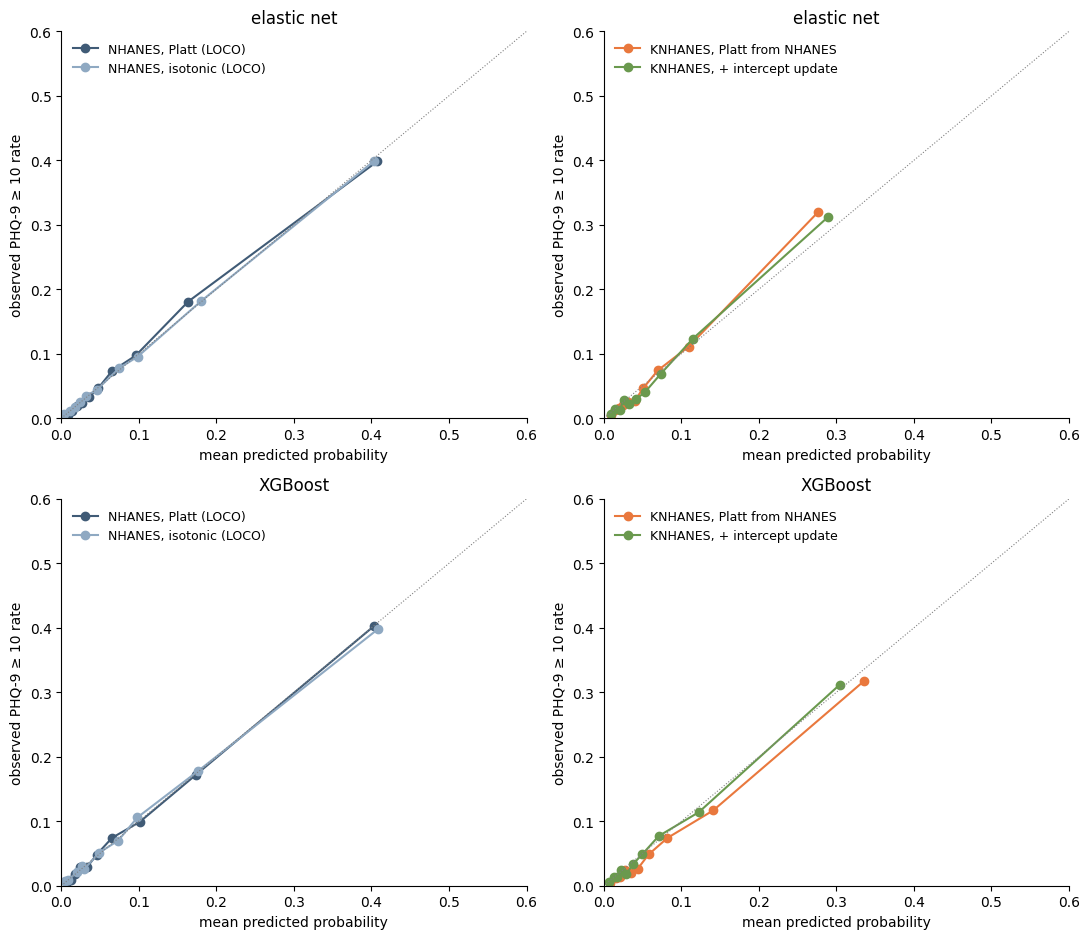

In [7]:
def bins(p, y, k=10):
    d = pd.DataFrame({"p": p, "y": y})
    q = pd.qcut(d.p, k, duplicates="drop")
    return d.groupby(q, observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))


fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for row, model in zip(axes, NAMES):
    h, g = nh_cal[nh_cal.model == model], kr_cal[kr_cal.model == model]
    curves = [(row[0], "NHANES, Platt (LOCO)", h.platt, h.depression, "#405B76"),
              (row[0], "NHANES, isotonic (LOCO)", h.isotonic, h.depression, "#8FA9C2"),
              (row[1], "KNHANES, Platt from NHANES", g.transported, g.depression, "#E9783D"),
              (row[1], "KNHANES, + intercept update", g.updated, g.depression, "#6A994E")]
    for ax, label, p, y, color in curves:
        b = bins(p, y)
        ax.plot(b.pred, b.obs, "o-", color=color, label=label)
    for ax in row:
        top = 0.6
        ax.plot([0, top], [0, top], color="grey", lw=0.8, ls=":")
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        ax.set_xlabel("mean predicted probability")
        ax.set_ylabel("observed PHQ-9 ≥ 10 rate")
        ax.set_title(NAMES[model])
        ax.legend(frameon=False, fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plots.show()

## Conclusions

- **NHANES:** Platt scaling turns the scores into probabilities: mean prediction 0.089 for an observed 0.089, slope 1.00, Brier 0.160 → 0.066 (elastic net) and 0.153 → 0.066 (XGBoost), AUROC unchanged. Isotonic regression is no better. Per test cycle the calibration intercept ranges from −0.39 (2005–06, the cycle with the lowest rate, 6.2%) to +0.15, which is the normal year-to-year variation within one country.
- **KNHANES, Platt from NHANES unchanged:**
  - Elastic net is calibrated on the pooled years: mean prediction 0.065 for an observed 0.066, intercept 0.02.
  - XGBoost is 16% too high (0.077 for 0.066, intercept −0.19).
  - Per year, 2014 is slightly too low and 2016 too high (intercepts +0.17 / −0.11 for elastic net, −0.05 / −0.32 for XGBoost), within the range NHANES shows between its own cycles.
  - The roughly 5-fold excess of the raw scores in Korea (4-fold in NHANES) therefore comes almost entirely from the class weights, not from the change of country.
- **The calibration slope in Korea is above 1:** 1.18 for elastic net (1.10 in 2014, 1.27 in 2016) and 1.07 for XGBoost. So the predictions are not too extreme, if anything too cautious: people at high predicted risk are depressed somewhat more often than predicted, and those at low predicted risk less often.
- **Intercept update from the other KNHANES year does not help.** The two years are off in opposite directions, so a shift learned on one year pushes the other the wrong way: per-year |intercept| grows from 0.11–0.17 to 0.28 for elastic net. Pooled, the update averages out to about the same as no update. (The pooled AUROC after the update, 0.819 / 0.821, is lower only because the two years get different shifts; within each year AUROC is unchanged.)
- **In short:** once the class weights are undone on NHANES, the probabilities carry over to Korea without further adjustment. The remaining error is about as large as the difference between two NHANES cycles, and a few thousand Korean people from another year do not reduce it.